# GDP growth forecasting: models and validation

Author: Sami Haroon Khan (modelling and validation workstream)

Input: the four time-based split CSVs in `../merged_data/merged_data/`. Every row is one country and one input year t, and the target `next_year_gdp_growth` is GDP growth in year t+1.

Order of the notebook:
1. Load the data, add lag features, run leakage checks.
2. Add the region and income group for each country.
3. Build a naive baseline and 4 models, tune them on 2018-2019, then test on 2020 and 2021-2024.
4. Feature importance and the report figures.
5. Comparison with the IMF forecasts.

## 1. Load the four splits into one panel

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA = Path("../merged_data/merged_data")
OUT = Path("outputs")
(OUT / "figures").mkdir(parents=True, exist_ok=True)

files = {"train": "GDP_Training_2001_2017.csv", "val": "GDP_Validation_2018_2019.csv",
         "covid": "GDP_COVID_2020.csv", "test": "GDP_Testing_2021_2024.csv"}
panel = pd.concat([pd.read_csv(DATA / f).assign(split=s) for s, f in files.items()], ignore_index=True)
panel = panel.sort_values(["Country Code", "Year"]).reset_index(drop=True)
TARGET = "next_year_gdp_growth"
panel.groupby("split").size()

split
covid     217
test      868
train    3689
val       434
dtype: int64

## Leakage checks

- Every country must have all 24 input years (2000-2023), so that "the row above" really means "last year".
- The target year must always be the input year + 1.
- The four splits must not share any target year.

In [2]:
assert panel.groupby("Country Code")["Year"].apply(lambda y: list(y) == list(range(2000, 2024))).all()
assert (panel["target_year"] == panel["Year"] + 1).all()
yrs = panel.groupby("split")["target_year"].agg(["min", "max"])
assert yrs.loc["train", "max"] < yrs.loc["val", "min"] <= yrs.loc["val", "max"] < yrs.loc["covid", "min"] < yrs.loc["test", "min"]
yrs

,min,max
split,,
covid,2020,2020
test,2021,2024
train,2001,2017
val,2018,2019


## Lag features and filling gaps from the past

- Two extra features: last year's growth (`gdp_growth_lag1`), and the average growth over the last 3 years (`gdp_growth_avg3`). That brings the total to 10 features, within the guideline of about 10.
- A gap is filled with the same country's most recent earlier value. The rows are sorted by year, so this never looks into the future.
- The naive baseline guesses that next year's growth equals this year's growth.

In [3]:
g = panel.groupby("Country Code")["gdp_growth"]
panel["gdp_growth_lag1"] = g.shift(1)
panel["gdp_growth_avg3"] = g.transform(lambda s: s.rolling(3, min_periods=2).mean())

BASE = ["gdp_growth", "inflation", "unemployment", "trade", "investment",
        "population_growth", "government_debt", "current_account"]
FEATURES = BASE + ["gdp_growth_lag1", "gdp_growth_avg3"]

panel[FEATURES] = panel.groupby("Country Code")[FEATURES].ffill()
panel["naive"] = panel["gdp_growth"]
panel[FEATURES].isna().mean().mul(100).round(1).rename("% still missing")

gdp_growth            3.4
inflation            14.6
unemployment         13.8
trade                15.5
investment           18.8
population_growth     0.0
government_debt      14.2
current_account      13.6
gdp_growth_lag1       7.5
gdp_growth_avg3       7.9
Name: % still missing, dtype: float64

## 2. Region and income group

These come from the public World Bank country API. They are fetched once and saved to `outputs/country_groups.csv`, so the notebook runs offline after that.

Limitation: this is today's income classification, applied to every year.

In [4]:
gfile = OUT / "country_groups.csv"
if not gfile.exists():
    import requests
    js = requests.get("https://api.worldbank.org/v2/country?format=json&per_page=400", timeout=30).json()[1]
    pd.DataFrame([{"Country Code": c["id"], "region": c["region"]["value"],
                   "income_group": c["incomeLevel"]["value"]} for c in js]).to_csv(gfile, index=False)
groups = pd.read_csv(gfile)
missing = set(panel["Country Code"]) - set(groups["Country Code"])
assert not missing, missing
groups[groups["Country Code"].isin(panel["Country Code"])]["income_group"].value_counts()

income_group
High income            86
Upper middle income    59
Lower middle income    47
Low income             25
Name: count, dtype: int64

## 3. Models

### Outliers
The training data includes hyperinflation (514%) and growth of +87%. Each feature is clipped at its 1st and 99th percentile, and those cut-offs come from the training years only. The target is never clipped.

In [5]:
tr = panel["split"] == "train"
lo = panel.loc[tr, FEATURES].quantile(0.01)
hi = panel.loc[tr, FEATURES].quantile(0.99)
panel[FEATURES] = panel[FEATURES].clip(lo, hi, axis=1)
pd.DataFrame({"low": lo, "high": hi}).round(1)

,low,high
gdp_growth,-10.9,17.3
inflation,-2.4,44.4
unemployment,0.6,27.7
trade,22.6,358.7
investment,3.6,52.8
population_growth,-2.0,6.1
government_debt,2.0,225.3
current_account,-32.0,40.7
gdp_growth_lag1,-11.0,17.3
gdp_growth_avg3,-7.9,14.4


### Pipeline and candidate settings

- The median imputer and the scaler sit inside the pipeline, so they are fitted only on the rows the model is trained on.
- Gradient Boosting uses Huber loss so that extreme years matter less.
- Every model is scored on the same rows: the rows where both the actual value and the naive guess exist.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

def make_pipe(model):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)

CANDIDATES = {
    "Ridge": [Ridge(alpha=a) for a in (0.1, 1, 10, 100)],
    "Lasso": [Lasso(alpha=a, max_iter=10000) for a in (0.01, 0.05, 0.1, 0.5)],
    "RandomForest": [RandomForestRegressor(n_estimators=300, max_depth=d, min_samples_leaf=5,
                                           random_state=42, n_jobs=-1) for d in (4, 8, None)],
    "GradientBoosting": [GradientBoostingRegressor(n_estimators=n, learning_rate=0.05, max_depth=3,
                                                   loss="huber", random_state=42) for n in (100, 300)],
}

def mae(y, p): return float(np.mean(np.abs(y - p)))
def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))

scored = panel.dropna(subset=[TARGET, "naive"])
train, val = scored[scored.split == "train"], scored[scored.split == "val"]
print("train rows:", len(train), " validation rows:", len(val))

train rows: 3500  validation rows: 421


### Tuning: train on 2001-2017, score on 2018-2019

For each model, the setting with the lowest validation MAE is kept.

In [7]:
best, tuning = {}, []
for name, cands in CANDIDATES.items():
    scores = []
    for m in cands:
        p = make_pipe(m).fit(train[FEATURES], train[TARGET]).predict(val[FEATURES])
        scores.append(mae(val[TARGET], p))
        keys = ("n_estimators",) if name == "GradientBoosting" else ("alpha", "max_depth")
        tuned = {k: v for k, v in m.get_params(deep=False).items() if k in keys}
        tuning.append({"model": name, "setting": str(tuned), "val_MAE": round(scores[-1], 3)})
    best[name] = cands[int(np.argmin(scores))]
print("naive validation MAE:", round(mae(val[TARGET], val["naive"]), 3))
pd.DataFrame(tuning)

naive validation MAE: 2.161


,model,setting,val_MAE
0,Ridge,{'alpha': 0.1},1.904
1,Ridge,{'alpha': 1},1.904
2,Ridge,{'alpha': 10},1.904
3,Ridge,{'alpha': 100},1.909
4,Lasso,{'alpha': 0.01},1.902
5,Lasso,{'alpha': 0.05},1.901
6,Lasso,{'alpha': 0.1},1.906
7,Lasso,{'alpha': 0.5},1.991
8,RandomForest,{'max_depth': 4},1.852
9,RandomForest,{'max_depth': 8},1.875


### Final fit and saved predictions

- The validation predictions come from the fit on 2001-2017.
- The COVID (2020) and test (2021-2024) predictions come from a refit on 2001-2019.
- Output: `outputs/predictions_all_models.csv`. This is the group's common evaluation table, with country, target year, actual, predicted, model, region and income group.

In [8]:
rows = []
def add(df, pred, model):
    rows.append(df[["Country Name", "Country Code", "target_year", "split"]]
                .assign(actual=df[TARGET].values, predicted=pred, model=model))

trval = scored[scored.split.isin(["train", "val"])]
later = scored[scored.split.isin(["covid", "test"])]
for name, m in best.items():
    add(val, make_pipe(m).fit(train[FEATURES], train[TARGET]).predict(val[FEATURES]), name)
    add(later, make_pipe(m).fit(trval[FEATURES], trval[TARGET]).predict(later[FEATURES]), name)
for part in (val, later):
    add(part, part["naive"].values, "Naive")

preds = pd.concat(rows, ignore_index=True).merge(groups, on="Country Code", how="left")
assert preds["region"].notna().all()
preds.to_csv(OUT / "predictions_all_models.csv", index=False, float_format="%.4f")
preds.shape

(7270, 9)

### Results

MAE is the main metric because a few extreme country-years dominate RMSE. Both metrics are in percentage points of GDP growth.

In [9]:
def score(d): return pd.Series({"MAE": mae(d.actual, d.predicted), "RMSE": rmse(d.actual, d.predicted), "n": len(d)})
metrics = preds.groupby(["split", "model"]).apply(score).round(3).reset_index()
by_year = preds.groupby(["target_year", "model"]).apply(score)["MAE"].unstack().round(2)
metrics.to_csv(OUT / "metrics_by_split.csv", index=False)
by_year.to_csv(OUT / "metrics_by_year.csv")
print(metrics.pivot(index="model", columns="split", values=["MAE", "RMSE"]))
by_year

                    MAE                  RMSE               
split             covid   test    val   covid    test    val
model                                                       
GradientBoosting  9.157  3.474  1.902  11.809   6.463  3.513
Lasso             9.086  3.705  1.901  11.755   6.748  3.409
Naive             8.652  5.813  2.161  11.234  10.536  5.162
RandomForest      8.973  3.487  1.852  11.717   6.352  3.455
Ridge             9.082  3.715  1.904  11.742   6.756  3.408


model,GradientBoosting,Lasso,Naive,RandomForest,Ridge
target_year,,,,,
2018,1.69,1.67,2.33,1.64,1.68
2019,2.12,2.13,1.99,2.06,2.13
2020,9.16,9.09,8.65,8.97,9.08
2021,5.71,6.39,11.92,5.52,6.42
2022,3.49,3.60,4.86,3.68,3.61
2023,2.65,2.81,3.89,2.72,2.81
2024,1.95,1.91,2.36,1.93,1.90


## 4. Feature importance

This uses permutation importance on the validation years, the same method for all 4 models: shuffle one feature and see how much the MAE gets worse. The Lasso coefficients show which features Lasso dropped (a coefficient of 0).

In [10]:
from sklearn.inspection import permutation_importance
imp = {}
for name, m in best.items():
    fitted = make_pipe(m).fit(train[FEATURES], train[TARGET])
    r = permutation_importance(fitted, val[FEATURES], val[TARGET], scoring="neg_mean_absolute_error",
                               n_repeats=20, random_state=42)
    imp[name] = r.importances_mean
imp = pd.DataFrame(imp, index=FEATURES).round(3)
imp.to_csv(OUT / "feature_importance.csv")

lasso_coef = pd.Series(make_pipe(best["Lasso"]).fit(train[FEATURES], train[TARGET])[-1].coef_, index=FEATURES)
imp.assign(lasso_coef=lasso_coef.round(3)).sort_values("GradientBoosting", ascending=False)

,Ridge,Lasso,RandomForest,GradientBoosting,lasso_coef
gdp_growth,0.649,0.639,0.634,0.515,1.639
gdp_growth_avg3,0.021,0.030,0.138,0.154,0.214
population_growth,0.028,0.025,0.006,0.051,0.295
unemployment,-0.001,0.000,-0.002,0.019,0.000
investment,0.006,0.001,-0.001,0.002,0.016
trade,0.004,0.000,0.000,-0.004,-0.010
gdp_growth_lag1,0.038,0.035,-0.006,-0.004,0.332
inflation,0.000,0.000,0.009,-0.005,0.000
government_debt,-0.004,0.000,0.007,-0.006,0.000
current_account,-0.001,0.000,0.000,-0.010,0.000


## Report figures

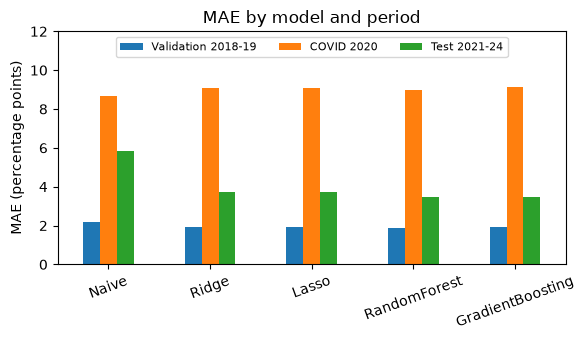

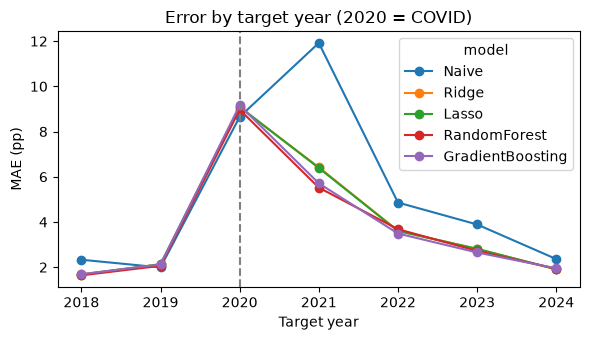

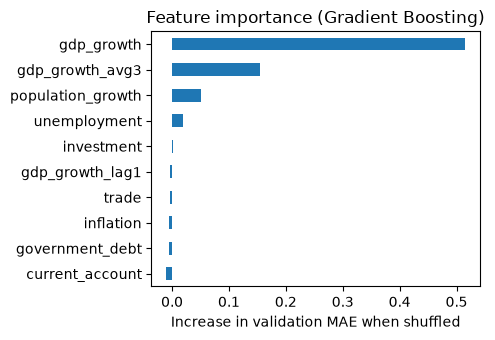

In [11]:
import matplotlib.pyplot as plt
order = ["Naive", "Ridge", "Lasso", "RandomForest", "GradientBoosting"]

ax = metrics.pivot(index="model", columns="split", values="MAE").loc[order, ["val", "covid", "test"]].plot.bar(figsize=(6, 3.5))
ax.set_ylabel("MAE (percentage points)"); ax.set_xlabel(""); ax.set_title("MAE by model and period")
ax.set_ylim(0, 12); ax.legend(["Validation 2018-19", "COVID 2020", "Test 2021-24"], ncol=3, loc="upper center", fontsize=8)
plt.xticks(rotation=20); plt.tight_layout(); plt.savefig(OUT / "figures/mae_by_model.png", dpi=200); plt.show()

ax = by_year[order].plot(marker="o", figsize=(6, 3.5))
ax.axvline(2020, ls="--", c="grey"); ax.set_ylabel("MAE (pp)"); ax.set_xlabel("Target year")
ax.set_title("Error by target year (2020 = COVID)")
plt.tight_layout(); plt.savefig(OUT / "figures/mae_by_year.png", dpi=200); plt.show()

ax = imp["GradientBoosting"].sort_values().plot.barh(figsize=(5, 3.5))
ax.set_xlabel("Increase in validation MAE when shuffled"); ax.set_title("Feature importance (Gradient Boosting)")
plt.tight_layout(); plt.savefig(OUT / "figures/feature_importance.png", dpi=200); plt.show()

## 5. Comparison with the IMF forecasts

This needs Farhana's file `../merged_data/imf_benchmark/imf_forecasts.csv` with the columns `Country Code, target_year, imf_forecast`. Each forecast should be the October WEO of year t for year t+1. All models are scored only on the rows the IMF covers, so the comparison is like for like. If the file isn't there yet, this cell just says so.

In [12]:
imf_file = DATA.parent / "imf_benchmark" / "imf_forecasts.csv"
if imf_file.exists():
    imf = pd.read_csv(imf_file)
    m = preds.merge(imf, on=["Country Code", "target_year"], how="inner")
    imf_rows = m.drop_duplicates(["Country Code", "target_year"]).assign(model="IMF", predicted=lambda d: d.imf_forecast)
    both = pd.concat([m, imf_rows], ignore_index=True)
    vs_imf = both.groupby(["split", "model"]).apply(score).round(3).reset_index()
    vs_imf.to_csv(OUT / "metrics_vs_imf.csv", index=False)
    display(vs_imf.pivot(index="model", columns="split", values="MAE"))
else:
    print("IMF benchmark file not in the repo yet:", imf_file)

IMF benchmark file not in the repo yet: ../merged_data/imf_benchmark/imf_forecasts.csv
